# Control óptimo de EDOs — Clase 8
**Tiempo mínimo, LQ–Riccati y programación dinámica**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 1. Tiempo mínimo para el doble integrador: realimentación
$u(x)=-\operatorname{sgn}(x_1+\frac12x_2|x_2|)$. Simulamos desde varios puntos y medimos el tiempo de llegada.

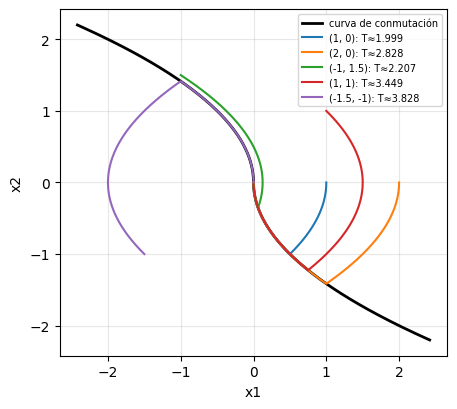

Desde (1,0) la teoría da T = 2.


In [3]:
def llegar(x1, x2, h=1e-4, tmax=20):
    tray = [(x1, x2)]; T = 0.0
    while x1**2 + x2**2 > 1e-6 and T < tmax:
        s = x1 + 0.5*x2*abs(x2)
        u = -np.sign(s) if abs(s) > 1e-9 else -np.sign(x2)
        x1, x2 = x1 + h*x2, x2 + h*u; T += h; tray.append((x1, x2))
    return T, np.array(tray)

s = np.linspace(-2.2, 2.2, 300)
plt.figure(figsize=(5, 4.5)); plt.plot(-s*np.abs(s)/2, s, 'k', lw=2, label='curva de conmutación')
for p in [(1, 0), (2, 0), (-1, 1.5), (1, 1), (-1.5, -1)]:
    T, tr = llegar(*p); plt.plot(tr[:, 0], tr[:, 1], label=f'{p}: T≈{T:.3f}')
plt.legend(fontsize=7); plt.xlabel('x1'); plt.ylabel('x2'); plt.show()
print('Desde (1,0) la teoría da T = 2.')

## 2. Riccati hacia atrás vs. la solución de la Clase 2
$\dot P=P^2-2P-3$, $P(1)=0$; $u=-Px$.

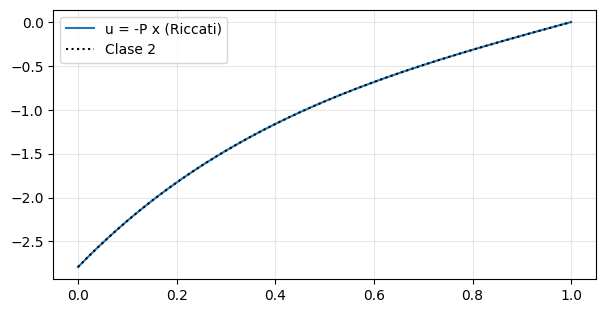

P(0) = 2.7916599606720944    3d - c = 2.7916599753100626    error máx en u: 9.488527237810906e-07


In [4]:
sP = solve_ivp(lambda t, P: P**2 - 2*P - 3, [1, 0], [0.0], dense_output=True, rtol=1e-11)
P = lambda t: sP.sol(t)[0]
sx = solve_ivp(lambda t, x: x - P(t)*x, [0, 1], [1.0], dense_output=True, rtol=1e-11)   # lazo cerrado
c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
tt = np.linspace(0, 1, 200)
u_riccati = -P(tt)*sx.sol(tt)[0]; u_clase2 = c*np.exp(2*tt) - 3*d*np.exp(-2*tt)
plt.plot(tt, u_riccati, label='u = -P x (Riccati)'); plt.plot(tt, u_clase2, 'k:', label='Clase 2')
plt.legend(); plt.show()
print('P(0) =', P(0), '   3d - c =', 3*d - c, '   error máx en u:', np.abs(u_riccati - u_clase2).max())

**Robustez de la realimentación:** perturbamos el estado a mitad de camino. El control en lazo abierto
(la función $u^*(t)$ precalculada) no se entera; el de lazo cerrado $u=-P(t)x$ sí.

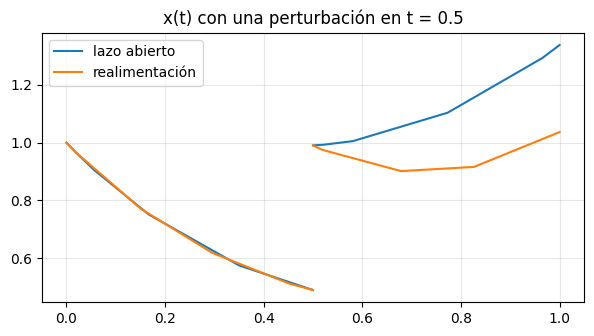

In [5]:
def simular_con_golpe(feedback):
    def rhs(t, x):
        u = -P(t)*x[0] if feedback else np.interp(t, tt, u_clase2)
        return [x[0] + u]
    s1 = solve_ivp(rhs, [0, 0.5], [1.0], dense_output=True, rtol=1e-9)
    s2 = solve_ivp(rhs, [0.5, 1], [s1.y[0, -1] + 0.5], dense_output=True, rtol=1e-9)   # golpe +0.5
    return s1, s2
for fb, nom in [(False, 'lazo abierto'), (True, 'realimentación')]:
    s1, s2 = simular_con_golpe(fb)
    plt.plot(s1.t, s1.y[0], 'C0' if not fb else 'C1'); plt.plot(s2.t, s2.y[0], 'C0' if not fb else 'C1', label=nom)
plt.legend(); plt.title('x(t) con una perturbación en t = 0.5'); plt.show()

## 3. LQR en horizonte infinito: péndulo invertido linealizado
$\dot x = Ax+Bu$, $A=\begin{pmatrix}0&1\\1&0\end{pmatrix}$, $B=\binom01$, $Q=I$, $R=1$.

P_inf =
 [[3.41421356 2.41421356]
 [2.41421356 2.41421356]] 
ganancia K = [[2.41421356 2.41421356]]
autovalores de A: [ 1. -1.]   de A - BK: [-1.         -1.41421356]


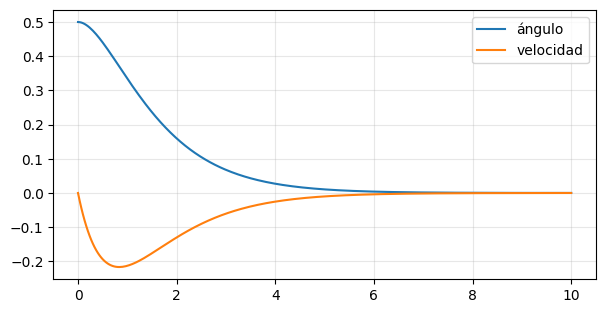

In [6]:
from scipy.linalg import solve_continuous_are
A = np.array([[0., 1.], [1., 0.]]); B = np.array([[0.], [1.]]); Q = np.eye(2); R = np.array([[1.]])
Pinf = solve_continuous_are(A, B, Q, R); K = np.linalg.solve(R, B.T @ Pinf)
print('P_inf =\n', Pinf, '\nganancia K =', K)
print('autovalores de A:', np.linalg.eigvals(A), '  de A - BK:', np.linalg.eigvals(A - B @ K))
s = solve_ivp(lambda t, x: (A - B @ K) @ x, [0, 10], [0.5, 0.0], t_eval=np.linspace(0, 10, 300))
plt.plot(s.t, s.y[0], label='ángulo'); plt.plot(s.t, s.y[1], label='velocidad'); plt.legend(); plt.show()

## 4. HJB por diferencias finitas (1D)
Para el LQ de la Clase 2 (versión máximo) la ecuación de HJB es
$-V_t=\max_v\{-\tfrac12(3x^2+v^2)+V_x(x+v)\}=-\tfrac32x^2+xV_x+\tfrac12V_x^2$, $V(1,x)=0$.
La resolvemos hacia atrás con un esquema explícito y comparamos con $V=-\frac12P(t)x^2$.

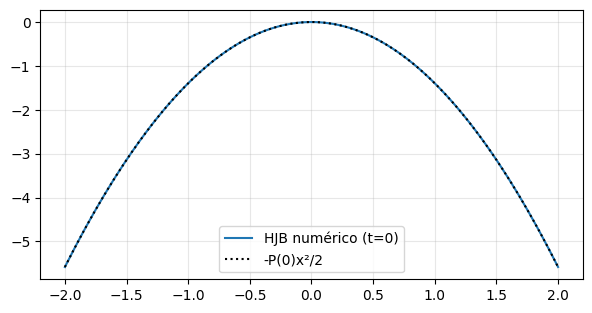

error máx en |x|<=1: 0.0002109117824848905


In [7]:
xs = np.linspace(-2, 2, 201); dx = xs[1] - xs[0]; dt = 2e-5; nt = int(1/dt)
V = np.zeros_like(xs)
for n in range(nt):
    Vx = np.gradient(V, dx)
    V = V + dt*(-1.5*xs**2 + xs*Vx + 0.5*Vx**2)
    V[0] = 2*V[1] - V[2]; V[-1] = 2*V[-2] - V[-3]          # extrapolación en el borde
ref = -0.5*P(0)*xs**2
interior = np.abs(xs) <= 1
plt.plot(xs, V, label='HJB numérico (t=0)'); plt.plot(xs, ref, 'k:', label='-P(0)x²/2'); plt.legend(); plt.show()
print('error máx en |x|<=1:', np.abs(V - ref)[interior].max())

## Para explorar
1. Repetir la sección 4 con una malla más fina o más gruesa. ¿Qué pasa si `dt` es muy grande? (condición CFL)
2. Con $Q=\mathrm{diag}(10,1)$ o $R=10$ en el péndulo, ¿cómo cambia la respuesta?
3. ¿Cuántos puntos necesitaría la grilla de HJB en dimensión 4 con 200 puntos por eje? (maldición de la dimensión)